In [1]:
import numpy as np
import pandas as pd

In [2]:
# !wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

In [3]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [5]:
df.isna().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [6]:
df = df.fillna(0)
df.isna().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [7]:
from sklearn.model_selection import train_test_split


df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
y_full_train = df_full_train.fuel_efficiency_mpg.values
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values



In [9]:
del df_full_train['fuel_efficiency_mpg']
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [10]:
df_train.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration
4495,2011,USA,Gasoline,Front-wheel drive,4,2370,6,284.0,4280,19.0
6470,2012,USA,Diesel,All-wheel drive,3,2460,6,288.0,4580,18.8
2221,1985,Europe,Gasoline,All-wheel drive,3,2070,6,230.0,4150,20.6
7686,2005,Europe,Diesel,Front-wheel drive,5,2050,5,249.0,4120,0.0
9419,2004,Asia,Gasoline,Front-wheel drive,2,2160,6,241.0,4020,17.9


In [11]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=True)

In [12]:
dict_train = df_train.to_dict(orient='records')
dict_val = df_val.to_dict(orient='records')
dict_test = df_test.to_dict(orient='records')
dict_full_train = df_full_train.to_dict(orient='records')


X_train = dv.fit_transform(dict_train)
X_val = dv.transform(dict_val)
X_test = dv.transform(dict_test)
X_full_train = dv.transform(dict_full_train)
X_train.shape, X_val.shape, X_test.shape, X_full_train.shape

((6000, 16), (2000, 16), (2000, 16), (8000, 16))

In [13]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=1)

dt.fit(X=X_train, y=y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [14]:
list(dv.get_feature_names_out())

['acceleration',
 'drivetrain=All-wheel drive',
 'drivetrain=Front-wheel drive',
 'drivetrain=Rear-wheel drive',
 'engine_displacement',
 'fuel_type=Diesel',
 'fuel_type=Gasoline',
 'fuel_type=Hybrid',
 'horsepower',
 'model_year',
 'num_cylinders',
 'num_doors',
 'origin=Asia',
 'origin=Europe',
 'origin=USA',
 'vehicle_weight']

[Text(0.5, 0.75, 'model_year <= 1997.5\nsquared_error = 8.589\nsamples = 6000\nvalue = 30.012'),
 Text(0.25, 0.25, 'squared_error = 6.937\nsamples = 2716\nvalue = 28.614'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'squared_error = 7.002\nsamples = 3284\nvalue = 31.168'),
 Text(0.625, 0.5, '  False')]

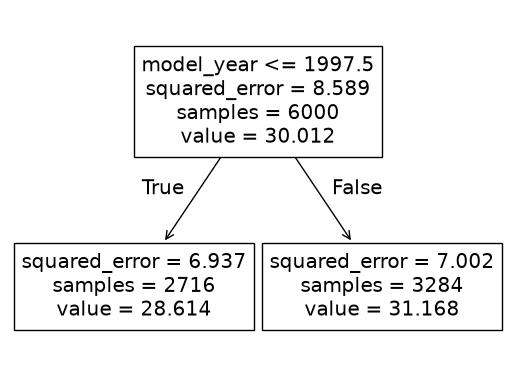

In [15]:
from sklearn.tree import plot_tree

plot_tree(dt, feature_names=dv.get_feature_names_out())

In [16]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [17]:
y_pred=rf.predict(X=X_val)
y_pred

array([28.06, 28.66, 31.92, ..., 29.25, 29.4 , 32.5 ], shape=(2000,))

In [18]:
from sklearn.metrics import mean_squared_error
from math import sqrt


rmse = sqrt(mean_squared_error(y_true=y_val, y_pred=rf.predict(X=X_val)))

rmse

1.8332197358745623

In [19]:
N = [10, 50, 100, 150]

rmses = []

for n in N:
    rfr = RandomForestRegressor(n_estimators=n, random_state=1)
    rfr.fit(X_train, y_train)
    rmse = sqrt(mean_squared_error(y_true=y_val, y_pred=rfr.predict(X=X_val)))
    rmses.append((rmse, n))

rmses


[(1.8332197358745623, 10),
 (1.7739880309630047, 50),
 (1.7697862961386044, 100),
 (1.7691982356737508, 150)]

In [20]:
min(rmses)

(1.7691982356737508, 150)

In [22]:
M = [10, 15, 20, 25]

mrmses = []

for m in M:
    rmses = []
    for n in N:
        rfr = RandomForestRegressor(n_estimators=n, max_depth=m, random_state=1)
        rfr.fit(X_train, y_train)
        rmse = sqrt(mean_squared_error(y_true=y_val, y_pred=rfr.predict(X=X_val)))
        rmses.append(rmse)
    mrmse = sum(rmses) / len(N)
    mrmses.append((mrmse, m))

mrmses



[(1.7543924943801008, 10),
 (1.784224344538596, 15),
 (1.786771187839516, 20),
 (1.7863054936840876, 25)]

In [23]:
min(mrmses)

(1.7543924943801008, 10)

In [30]:
rfr = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)

rfr.fit(X_train, y_train)

importances = pd.Series(
    rfr.feature_importances_,
    index=dv.get_feature_names_out()
)

In [31]:
importances

acceleration                    0.054998
drivetrain=All-wheel drive      0.007951
drivetrain=Front-wheel drive    0.020062
drivetrain=Rear-wheel drive     0.005638
engine_displacement             0.061281
fuel_type=Diesel                0.016571
fuel_type=Gasoline              0.160712
fuel_type=Hybrid                0.016272
horsepower                      0.078271
model_year                      0.296107
num_cylinders                   0.007318
num_doors                       0.019401
origin=Asia                     0.006515
origin=Europe                   0.003436
origin=USA                      0.042152
vehicle_weight                  0.203313
dtype: float64

In [32]:
options = [
    "vehicle_weight",
    "horsepower",
    "acceleration",
    "engine_displacement"
]

print(importances.loc[options].sort_values(ascending=False))

print("Answer:", importances.loc[options].idxmax())

vehicle_weight         0.203313
horsepower             0.078271
engine_displacement    0.061281
acceleration           0.054998
dtype: float64
Answer: vehicle_weight


In [35]:
import xgboost as xgb

features = list(dv.get_feature_names_out())

d_train = xgb.DMatrix(X_train, label=y_train, feature_names=features)
d_valid = xgb.DMatrix(X_val, label=y_val, feature_names=features)


In [36]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, d_train, num_boost_round=100)

In [38]:
y_pred = model.predict(d_valid)

In [39]:
y_pred

array([28.223745, 29.28878 , 31.806875, ..., 29.087856, 28.984459,
       31.72586 ], shape=(2000,), dtype=float32)

In [40]:
rmse = sqrt(mean_squared_error(y_true=y_val, y_pred=y_pred))
rmse

1.8264579799904583

In [41]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, d_train, num_boost_round=100)

In [42]:
y_pred = model.predict(d_valid)

In [43]:
rmse = sqrt(mean_squared_error(y_true=y_val, y_pred=y_pred))
rmse

1.724810059827976